# EDA datos Challenge Leaderboard

# Observaciones iniciales (Data Wrangler)
**Conclusiones obtenidas tras preguntarle dudas al profesor:**

- Los datos han de ser tratados como series temporales, ya que cada conjunto de datos corresponde a un movimiento realizado (ordenado mediante la columna `timestamp`).

- Se utilizan dos dispositivos de movimiento (`Commercial` y `Custom`). En un primer análisis no existe diferencia entre ellos, ya que ambos tienen el mismo sistema de referencia y mediciones parecidas. Por ello, podría ser una columna despreciable; como opción, se pueden realizar dos *pipelines* de datos: uno en el que se tenga en cuenta y otro en el que no.

- Cada dispositivo usado para la medición presenta un sistema de referencia propio (no hay uno conjunto). Por lo tanto, habría que realizar una metodología específica de detección de *outliers* para cada uno y así evitar errores en los datos.

Como propuesta, se pueden detectar los *outliers* mediante un modelo de *clustering* tridimensional, para ver si es posible realizarla vamos a analizar el conjunto de movimientos

# Agrupacion de movimientos

In [2]:

import sys
import numpy as np
import pandas as pd
import json

from pathlib import Path

sys.path.append("..")
from src.utils.utils import *

# Cargamos el dataset
df = load_data_csv(r'..\data\raw\train.csv')

# Cargamos el dataset Summary
df_summary = load_json(r'..\data\dataset_summary.json')

## Representación de los movimientos en 3D (Por Sesión, Por Sensor y Por sujeto)
Atendiendo al siguinte sistema de coordenadas (X -> Sentido -Z / Y -> Y  / Z -> X ) Se ha realizado una rotación en Y de 90º Horaria

#### POR SUJETO

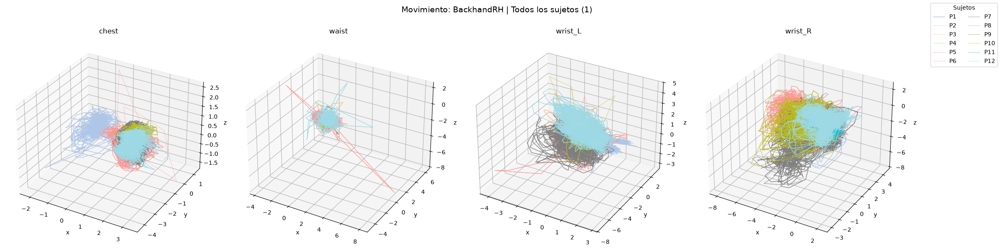

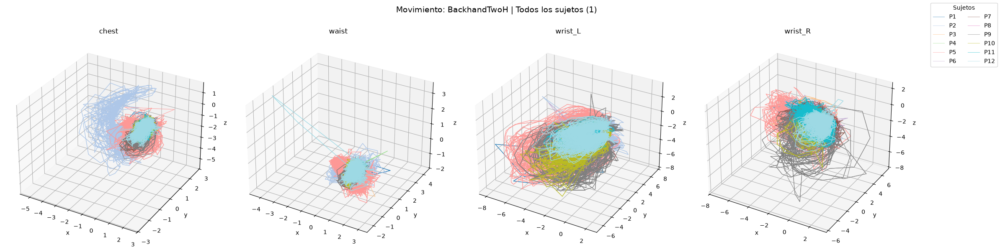

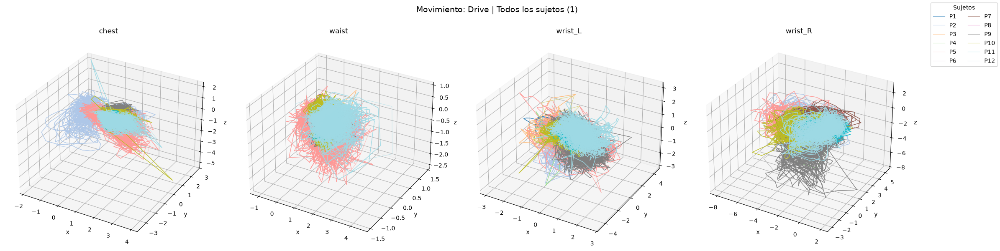

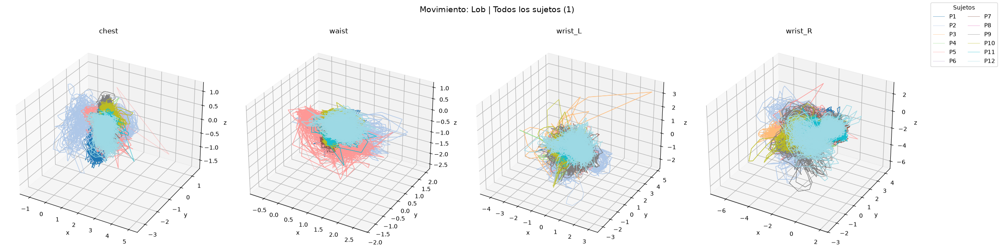

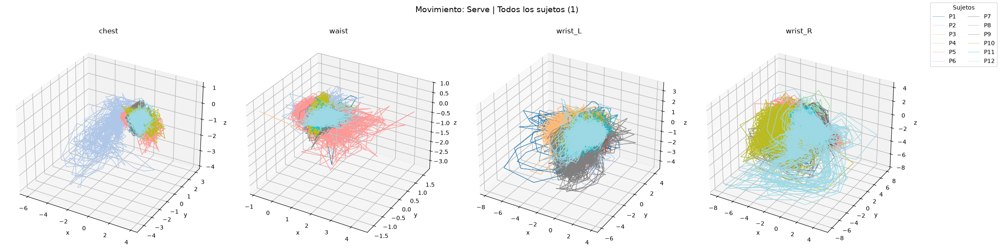

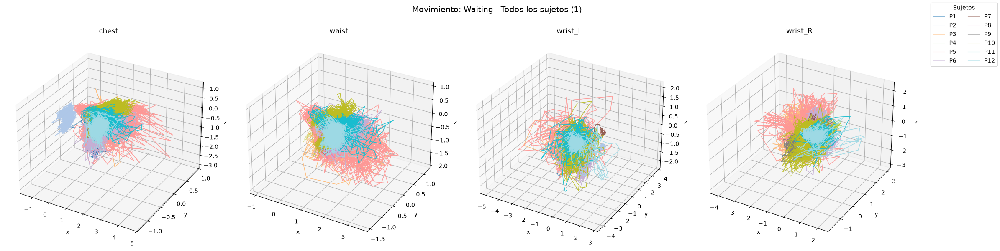

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

Classes = df_summary["activity_classes"]
subjects = list(df_summary["train_subject_distribution"].keys())[:]
sensores = list(df_summary["channel_names"])

articulaciones = []
for s in sensores:
    base = s[:-2] if s.endswith(("_x", "_y", "_z")) else s
    if base not in articulaciones:
        articulaciones.append(base)

cmap = plt.get_cmap("tab20", max(len(subjects), 1))
subject_colors = {
    subj: cmap(i) for i, subj in enumerate(subjects)
}

for type_class in Classes:

    df_class = df[df["label"] == type_class].copy()

    if df_class.empty:
        continue

    for start in range(0, len(articulaciones), 4):

        bloque = articulaciones[start:start + 4]

        fig, axes = plt.subplots(
            1, 4,
            figsize=(24, 6),
            subplot_kw={"projection": "3d"}
        )

        fig.suptitle(
            f"Movimiento: {type_class} | Todos los sujetos "
            f"({start // 4 + 1})",
            fontsize=14
        )

        for idx, ax in enumerate(axes):

            ax.grid(True)

            if idx >= len(bloque):
                ax.set_visible(False)
                continue

            sensor = bloque[idx]

            cols_x = [
                f"{sensor}_x_t{t}"
                for t in range(200)
                if f"{sensor}_x_t{t}" in df_class.columns
            ]

            cols_y = [
                f"{sensor}_y_t{t}"
                for t in range(200)
                if f"{sensor}_y_t{t}" in df_class.columns
            ]

            cols_z = [
                f"{sensor}_z_t{t}"
                for t in range(200)
                if f"{sensor}_z_t{t}" in df_class.columns
            ]

            if not (cols_x and cols_y and cols_z):
                continue

            for subject in subjects:

                df_subj = df_class[
                    df_class["subject_id"].astype(str) == str(subject)
                ]

                if df_subj.empty:
                    continue

                arr_x = df_subj[cols_x].to_numpy(dtype=float)
                arr_y = df_subj[cols_y].to_numpy(dtype=float)
                arr_z = df_subj[cols_z].to_numpy(dtype=float)

                # Todas las trayectorias individuales
                for i in range(len(df_subj)):

                    ax.plot(
                        arr_x[i],
                        arr_y[i],
                        arr_z[i],
                        color=subject_colors[subject],
                        linewidth=0.8,
                        alpha=0.5,
                        label=str(subject) if i == 0 else None
                    )

            ax.set_title(sensor)
            ax.set_xlabel("x")
            ax.set_ylabel("y")
            ax.set_zlabel("z")

        # Leyenda ordenada por sujeto
        handles_dict = {}

        for ax in axes:
            if not ax.get_visible():
                continue

            handles, labels = ax.get_legend_handles_labels()

            for handle, label in zip(handles, labels):
                if label not in handles_dict:
                    handles_dict[label] = handle

        labels_ordered = [
            str(subject)
            for subject in subjects
            if str(subject) in handles_dict
        ]

        handles_ordered = [
            handles_dict[label]
            for label in labels_ordered
        ]

        if handles_ordered:
            fig.legend(
                handles_ordered,
                labels_ordered,
                loc="upper right",
                ncol=2,
                title="Sujetos"
            )

        plt.tight_layout(rect=[0, 0, 0.92, 0.94])
        plt.show()


#### Por sesión y sensor (Sujeto 1)

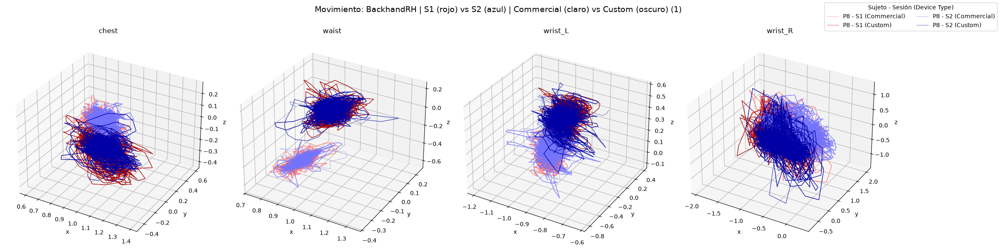

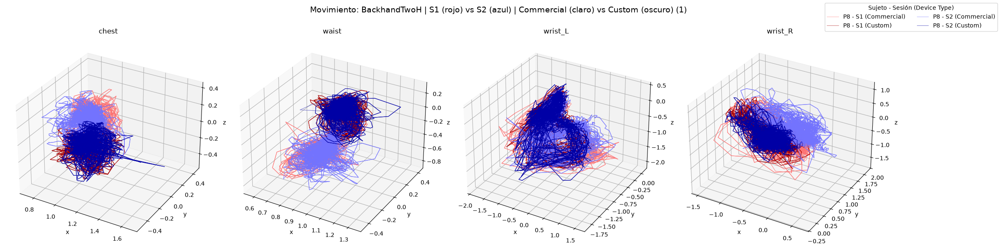

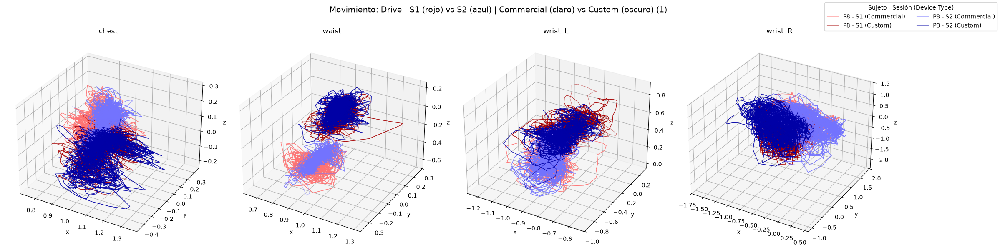

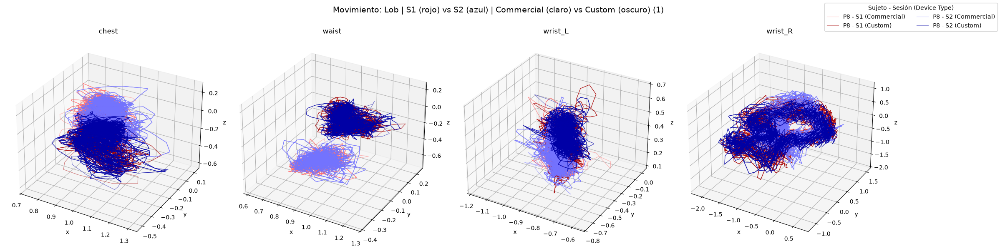

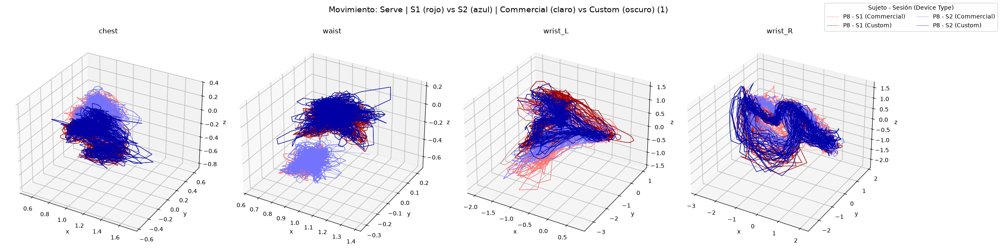

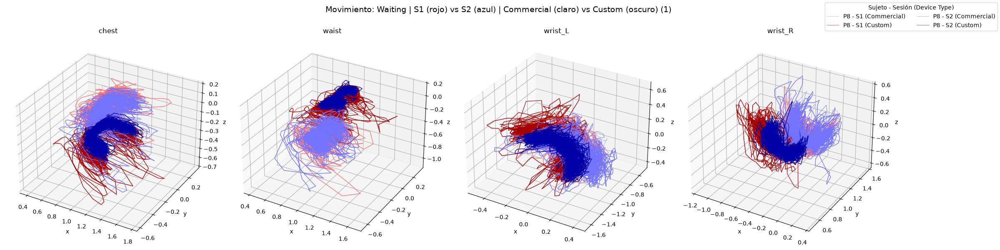

In [11]:



import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

Classes = df_summary["activity_classes"]

# SELECCIÓN DE SUJETOS
subjects = list(df_summary["train_subject_distribution"].keys())[7:8]
subjects = [str(s) for s in subjects]

# SESIONES Y DISPOSITIVOS
sessions = ["S1", "S2"]
device_types = ["Commercial", "Custom"]

session_colors = {
    "S1": "red",
    "S2": "blue"
}

sensores = list(df_summary["channel_names"])

articulaciones = []
for s in sensores:
    base = s[:-2] if s.endswith(("_x", "_y", "_z")) else s
    if base not in articulaciones:
        articulaciones.append(base)


def ajustar_tono(color, factor, hacia_blanco=True):

    rgba = np.array(mcolors.to_rgba(color), dtype=float)

    objetivo = (
        np.array([1.0, 1.0, 1.0, rgba[3]])
        if hacia_blanco
        else np.array([0.0, 0.0, 0.0, rgba[3]])
    )

    resultado = rgba * (1.0 - factor) + objetivo * factor
    resultado[:3] = np.clip(resultado[:3], 0.0, 1.0)

    return tuple(resultado)


# COLORES POR SESIÓN Y TIPO DE DISPOSITIVO
colores = {}

for session in sessions:

    base_color = session_colors[session]

    colores[(session, "Commercial")] = ajustar_tono(
        base_color, 0.45, hacia_blanco=True
    )

    colores[(session, "Custom")] = ajustar_tono(
        base_color, 0.35, hacia_blanco=False
    )


df = df.copy()
df["subject_id"] = df["subject_id"].astype(str)

for type_class in Classes:

    df_class = df[df["label"] == type_class].copy()

    if df_class.empty:
        continue

    for start in range(0, len(articulaciones), 4):

        bloque = articulaciones[start:start + 4]

        fig, axes = plt.subplots(
            1, 4,
            figsize=(24, 6),
            subplot_kw={"projection": "3d"}
        )

        fig.suptitle(
            f"Movimiento: {type_class} | "
            f"S1 (rojo) vs S2 (azul) | "
            f"Commercial (claro) vs Custom (oscuro) "
            f"({start // 4 + 1})",
            fontsize=14
        )

        for idx, ax in enumerate(axes):

            ax.grid(True)

            if idx >= len(bloque):
                ax.set_visible(False)
                continue

            sensor = bloque[idx]

            # Instantes temporales disponibles en los tres ejes
            times = [
                t for t in range(200)
                if all(
                    f"{sensor}_{axis}_t{t}" in df_class.columns
                    for axis in ["x", "y", "z"]
                )
            ]

            if not times:
                continue

            cols_x = [f"{sensor}_x_t{t}" for t in times]
            cols_y = [f"{sensor}_y_t{t}" for t in times]
            cols_z = [f"{sensor}_z_t{t}" for t in times]

            for subject in subjects:

                df_subj = df_class[
                    df_class["subject_id"] == subject
                ]

                if df_subj.empty:
                    continue

                for session in sessions:

                    df_session = df_subj[
                        df_subj["session"] == session
                    ]

                    if df_session.empty:
                        continue

                    for dev_type in device_types:

                        df_dev = df_session[
                            df_session["device_type"] == dev_type
                        ]

                        if df_dev.empty:
                            continue

                        arr_x = df_dev[cols_x].to_numpy(dtype=float)
                        arr_y = df_dev[cols_y].to_numpy(dtype=float)
                        arr_z = df_dev[cols_z].to_numpy(dtype=float)

                        color = colores[(session, dev_type)]

                        for i in range(len(df_dev)):

                            ax.plot(
                                arr_x[i],
                                arr_y[i],
                                arr_z[i],
                                color=color,
                                linewidth=0.8,
                                alpha=0.5,
                                label=(
                                    f"{subject} - {session} ({dev_type})"
                                    if i == 0 else None
                                )
                            )

            ax.set_title(sensor)
            ax.set_xlabel("x")
            ax.set_ylabel("y")
            ax.set_zlabel("z")

        # LEYENDA ORDENADA:
        # S1 Commercial, S1 Custom, S2 Commercial, S2 Custom
        handles_dict = {}

        for ax in axes:
            if not ax.get_visible():
                continue

            handles, labels = ax.get_legend_handles_labels()

            for handle, label in zip(handles, labels):
                if label not in handles_dict:
                    handles_dict[label] = handle

        labels_ordered = [
            f"{subject} - {session} ({dev_type})"
            for subject in subjects
            for session in sessions
            for dev_type in device_types
            if f"{subject} - {session} ({dev_type})" in handles_dict
        ]

        handles_ordered = [
            handles_dict[label] for label in labels_ordered
        ]

        if handles_ordered:
            fig.legend(
                handles_ordered,
                labels_ordered,
                loc="upper right",
                ncol=2,
                title="Sujeto - Sesión (Device Type)"
            )

        plt.tight_layout(rect=[0, 0, 0.90, 0.94])
        plt.show()


**Como se puede observar en las gráficas mostradas, en las que se ha representado el conjunto de datos en el espacio cartesiano, existe una pequeña dispersión entre los puntos registrados por los diferentes sujetos. Esto puede deberse a que los participantes presentan distintas características físicas y diferentes formas de ejecutar un mismo movimiento. Por tanto, para realizar un correcto filtrado de los datos, se considera necesario aplicar filtros individualizados para cada sujeto, con el objetivo de eliminar los valores atípicos (*outliers*).**

**Sin embargo, al analizar los datos de un mismo sujeto según la sesión se puede observar que no existe una dispersión considerable entre los diferentes sensores y sesiones ne la gran mayoría de los susjetos. A excepción de ciertos sujetos que si que presentan una dispersión en una en la articualción de ''waist''. Es por ello que vamos a analizar la dispersión que se da en cada uno de los ejes**

#### Dispersión de los datos 

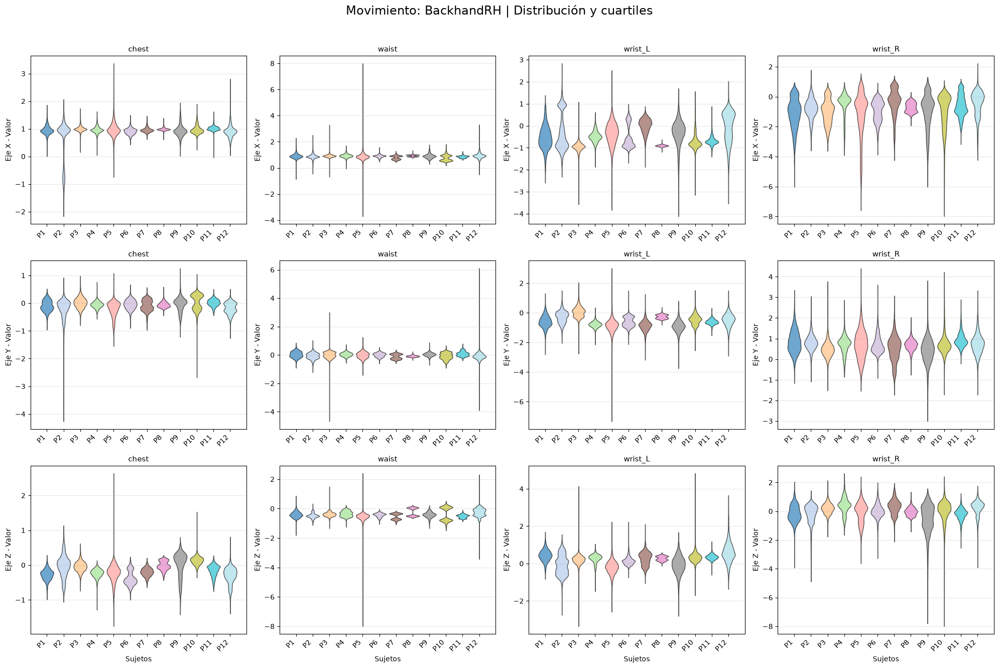

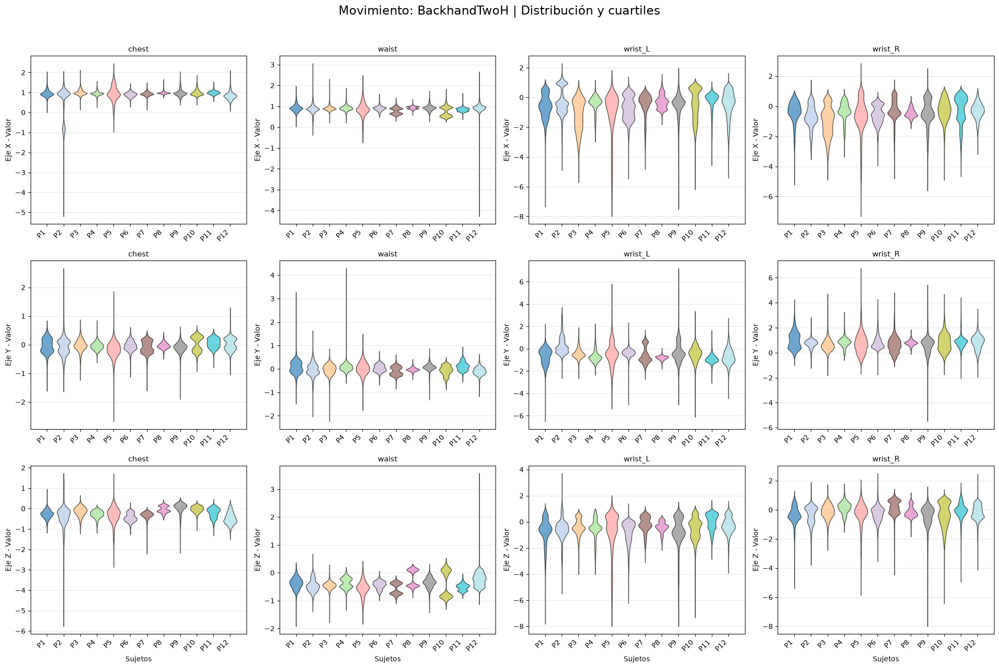

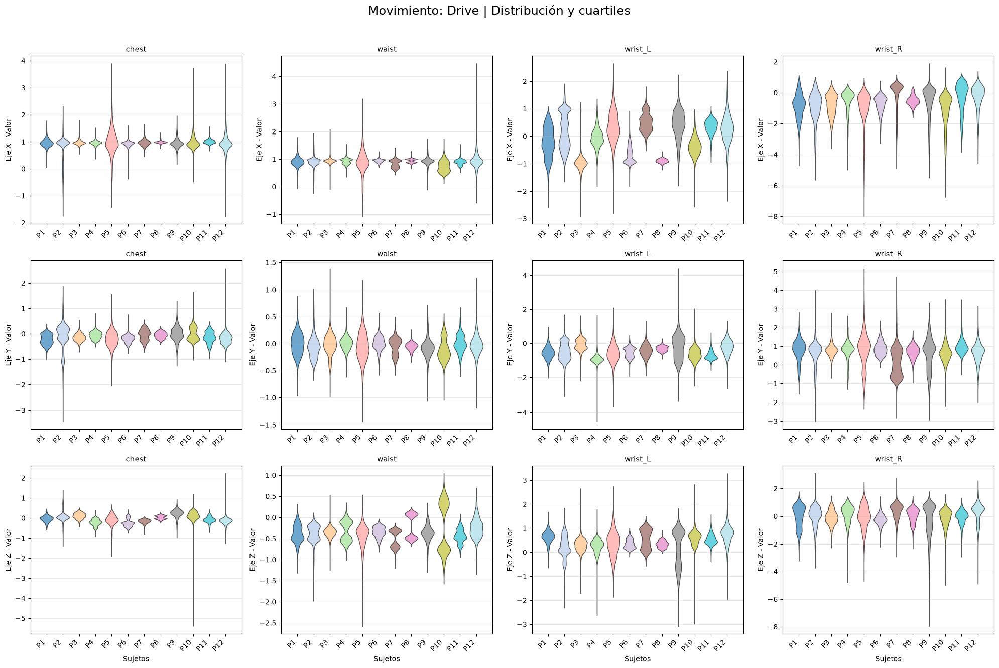

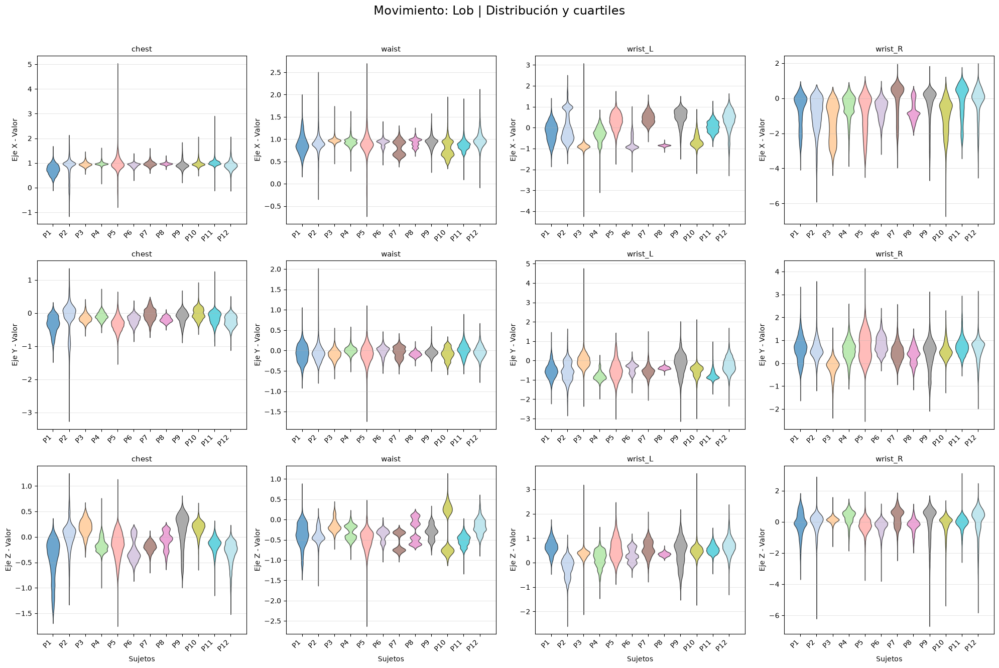

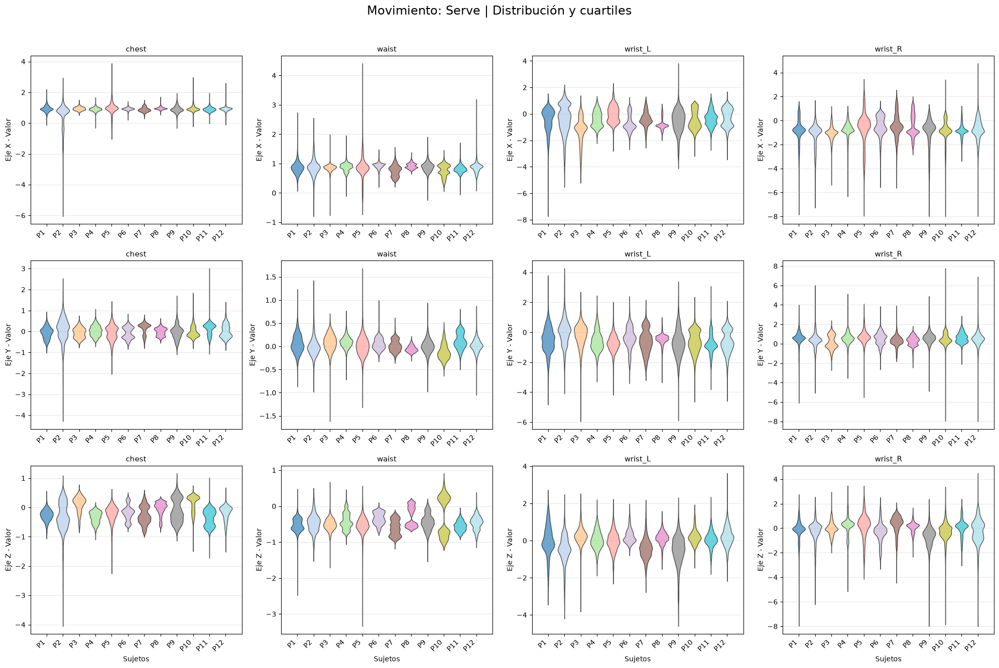

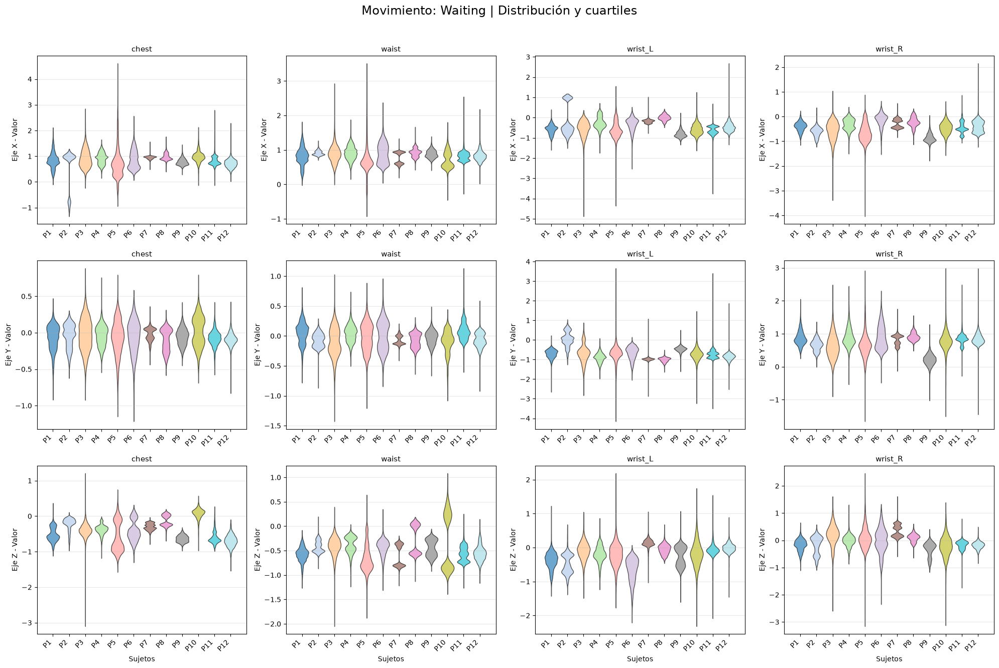

In [10]:

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

Classes = df_summary["activity_classes"]
subjects = list(df_summary["train_subject_distribution"].keys())
sensores = list(df_summary["channel_names"])

# Obtener articulaciones únicas
articulaciones = []
for s in sensores:
    base = s[:-2] if s.endswith(("_x", "_y", "_z")) else s
    if base not in articulaciones:
        articulaciones.append(base)

# Un color por sujeto
cmap = plt.get_cmap("tab20", max(len(subjects), 1))
subject_colors = {
    subj: cmap(i) for i, subj in enumerate(subjects)
}

# Una figura por movimiento
for type_class in Classes:

    df_class = df[df["label"] == type_class].copy()

    if df_class.empty:
        continue

    n_articulaciones = len(articulaciones)

    fig, axes = plt.subplots(
        3,
        n_articulaciones,
        figsize=(max(5 * n_articulaciones, 14), 13),
        squeeze=False
    )

    fig.suptitle(
        f"Movimiento: {type_class} | Distribución y cuartiles",
        fontsize=17,
        y=1.02
    )

    # Recorrer articulaciones
    for col, sensor in enumerate(articulaciones):

        # Recorrer ejes X, Y, Z
        for row, eje in enumerate(["x", "y", "z"]):

            ax = axes[row, col]

            datos_violin = []
            posiciones = []
            colores = []
            cuartiles = []

            # Obtener datos de cada sujeto
            for pos, subject in enumerate(subjects):

                df_subj = df_class[
                    df_class["subject_id"].astype(str) == str(subject)
                ]

                if df_subj.empty:
                    continue

                cols = [
                    f"{sensor}_{eje}_t{t}"
                    for t in range(200)
                    if f"{sensor}_{eje}_t{t}" in df_subj.columns
                ]

                if not cols:
                    continue

                valores = df_subj[cols].to_numpy(dtype=float).flatten()
                valores = valores[np.isfinite(valores)]

                if len(valores) == 0:
                    continue

                datos_violin.append(valores)
                posiciones.append(pos)
                colores.append(subject_colors[subject])

                # Calcular Q1, Q2 y Q3
                q1, q2, q3 = np.percentile(valores, [25, 50, 75])
                cuartiles.append((q1, q2, q3))

            # Dibujar violines
            if datos_violin:

                violin = ax.violinplot(
                    datos_violin,
                    positions=posiciones,
                    widths=0.8,
                    showmeans=False,
                    showmedians=False,
                    showextrema=False
                )

                # Colorear violines
                for body, color in zip(violin["bodies"], colores):
                    body.set_facecolor(color)
                    body.set_edgecolor("black")
                    body.set_alpha(0.65)

            # Personalización
            ax.set_title(sensor, fontsize=11)
            ax.set_ylabel(f"Eje {eje.upper()} - Valor")
            ax.grid(True, axis="y", alpha=0.3)

            ax.set_xticks(range(len(subjects)))
            ax.set_xticklabels(
                [str(s) for s in subjects],
                rotation=45,
                ha="right"
            )

            if row == 2:
                ax.set_xlabel("Sujetos")

    plt.tight_layout()
    plt.show()


**Analizando la dispersión presentada, se puede ver que la gran mayoría de los puntos presentan se encuentran concentradas en el mismo conjunto espacial. Sin embargo como se pudo ver en la representacion cartesiana, existen ciertos conjuntos que no presentan una agrupación conjunta si no que estan dispersos en dos grandes conjuntos separados por una separación considerable. Por tando para poder filtrar los ouliers vamos a hacer uso de un filtrado por Clustering.**

## Conversión del dataset a serie temporal unica

Ahora mismo el conjunto analizado se trata de una serie temporal donde cada registro (fila) se trata de otro serie temporal. Por lo que para poder trabajar en formato más c